# A Worst-of-Five Autocallable: Monte Carlo Pricing, Greeks and a Deep-Learning Surrogate Pricer

Autocallable notes pay generous coupons, and the reason is that the investor is quietly selling protection on the worst of several stocks. With five stocks, the chance that at least one of them falls a long way is much higher than it looks. This notebook prices a real-world note of this kind, shows where its risk sits, and replays it every month since 2006 to see what investors actually received.

**What it does.** It prices a two-year **worst-of autocallable note** on five U.S. stocks (Apple, Microsoft, Amazon, Alphabet, JPMorgan) with today's market data, finds its fair coupon, computes its Greeks and correlation risk, and replays the same note issued every month since 2006.

A **Keras neural network** is then trained on noisy Monte Carlo prices to act as a fast surrogate pricer. It values thousands of risk scenarios in milliseconds and is used for a historical-scenario VaR of the note.

**Data.** Yahoo Finance (prices since 2005, dividend yields, listed option chains for implied volatilities) and FRED (Treasury yields, VIX).

**Methods.** Correlated multi-asset Monte Carlo in PyTorch with antithetic variates and common random numbers, implied-volatility inversion and smile fitting, and bump-and-revalue Greeks.

A Keras 3 MLP surrogate trained on noisy labels feeds a historical-scenario VaR and ES.

**Key output.** Fair coupon, Greeks, correlation and skew sensitivities, the surrogate's accuracy and speed, 10-day VaR, and the distribution of realised outcomes since 2006.

## 1. The product

An **autocallable** pays a high coupon because the investor sells the issuer a put on the worst-performing stock. Its terms, per 100 of notional:

| feature | terms |
|---|---|
| underlyings | AAPL, MSFT, AMZN, GOOGL, JPM, measured by **the worst** performance against the issue-date fixing |
| maturity and observations | 2 years, observed quarterly (8 dates) |
| **autocall** | if on any observation date all five stocks are at or above 100% of their fixing, the note redeems at 100 plus the coupon, and stops |
| **conditional coupon with memory** | paid on an observation date if the worst stock is at or above 70%; missed coupons are paid later when the condition is met again |
| **capital protection** | at maturity, 100 if the worst stock is at or above 60% (European barrier); otherwise 100 × worst performance |

The coupon is what the market sets: it is the rate that makes the note worth its issue price (100) minus the issuer's margin.

**Why worst-of matters.** With five stocks, the chance that *at least one* falls below 60% is much higher than for any single stock. Lower correlation makes a big loser more likely and calls less likely, so the note is worth less. The investor is **long correlation**, and the issuer's desk, which holds the opposite position, is **short correlation**.

Correlation cannot be hedged with listed instruments, so this is the core risk of a structured-products book.

## 2. Setup

In [1]:
# --- macOS safety switch (must run before any scientific import)
# Several libraries (PyTorch, LightGBM, scikit-learn, NumPy builds) ship their
# own OpenMP runtime.
# On Apple Silicon two copies in one process can make Jupyter report "the
# kernel crashed".
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")
os.environ.setdefault("KERAS_BACKEND", "torch")

# --- Standard library
import datetime as dt
import io
import re
import time
import warnings
from pathlib import Path

# --- Third-party
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import requests
from dotenv import find_dotenv, load_dotenv
from fredapi import Fred
from plotly.subplots import make_subplots
import torch
import keras
import yfinance as yf
from keras import layers
from scipy.optimize import brentq
from scipy.stats import norm

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

PROJECT_DIR = Path.cwd()
DATA_DIR, OUT_DIR = PROJECT_DIR / "data", PROJECT_DIR / "outputs"
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

load_dotenv(find_dotenv(usecwd=True))
FRED_API_KEY = os.getenv("FRED_API_KEY", "").strip()
if not FRED_API_KEY:
    raise RuntimeError(
        "FRED_API_KEY not found. Create the .env file at the repo root (see"
        " .env.example)."
    )
fred = Fred(api_key=FRED_API_KEY)
BROWSER_HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0"
        " Safari/537.36"
    )
}

SEED = 17
rng = np.random.default_rng(SEED)
keras.utils.set_random_seed(SEED)
torch.set_num_threads(max(1, os.cpu_count() or 1))
TICKERS = ["AAPL", "MSFT", "AMZN", "GOOGL", "JPM"]
START = "2005-01-01"
# two-year note, quarterly observations
TENOR_YEARS, N_OBS = 2.0, 8
AUTOCALL, COUPON_BARRIER, KI_BARRIER = 1.00, 0.70, 0.60
# fair value the issuer targets: 100 minus a 2% margin (assumption)
ISSUE_PRICE = 98.0
# Monte Carlo paths for pricing and Greeks (half antithetic)
N_PATHS = 200_000
# trading days of returns behind the correlation matrix (two years)
CORR_WINDOW = 504
# surrogate: training samples and paths per (noisy) label
N_TRAIN, PATHS_TRAIN = 24_000, 4_096
# surrogate: test samples priced precisely
N_TEST, PATHS_TEST = 300, 131_072

print(
    f"torch {torch.__version__} · keras"
    f" {keras.__version__} ({keras.backend.backend()}) · yfinance"
    f" {yf.__version__} · run on {dt.date.today():%Y-%m-%d}"
)

torch 2.14.1+cu130 · keras 3.15.1 (torch) · yfinance 1.7.0 · run on 2026-10-20


In [2]:
# --- Caching helper: every download is stored in data/ and reused for 12 hours
def cached(name, fetch, max_age_hours=12):
    path = DATA_DIR / f"{name}.parquet"
    if (
        path.exists()
        and (time.time() - path.stat().st_mtime) / 3600 < max_age_hours
    ):
        return pd.read_parquet(path)
    try:
        frame = fetch()
        frame.to_parquet(path)
        return frame
    except Exception as err:
        if path.exists():
            print(
                f"⚠️  {name}: download failed ({type(err).__name__}); using"
                " cached copy"
            )
            return pd.read_parquet(path)
        raise


# --- Chart style
PALETTE = [
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#6250d6",
    "#e34948",
]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
STATUS = {"green": "#1baf7a", "amber": "#eda100", "red": "#e34948"}
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "grid.color": GRID,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "legend.frameon": False,
    "lines.linewidth": 2.0,
    "font.size": 10,
    "figure.dpi": 110,
    "axes.axisbelow": True,
})


def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def save_dashboard(dash, name):
    """
    Interactive HTML always; static PNG (for GitHub) when kaleido can find
    Chrome.
    """
    dash.write_html(OUT_DIR / f"{name}.html", include_plotlyjs="cdn")
    try:
        dash.write_image(OUT_DIR / f"{name}.png", scale=2)
        print(f"Dashboard saved: outputs/{name}.html and .png")
    except Exception as err:
        print(
            f"Dashboard saved as HTML; PNG skipped ({type(err).__name__}). Run"
            " `plotly_get_chrome` once."
        )


def tenor_label(t):
    return f"{int(round(t * 12))}M" if t < 1 else f"{t:g}Y"

## 3. Market data

- **Prices:** daily adjusted closes since 2005. The last two years of log returns give the **correlation matrix**.
- **Rates:** the 2-year Treasury yield (FRED), used flat for both drift and discounting; the 3-month and 1-year yields are shown for reference. These are risk-free rates; a real issuer discounts at its own funding rate, which is part of its margin.
- **Dividend yields:** from Yahoo, assumed continuous.
- **Implied volatility:** from the listed option chain of each stock at the expiry closest to two years. Mid prices of out-of-the-money puts and calls are inverted with Black–Scholes; Yahoo's own implied-volatility field is not used because it relies on stale last trades. A quadratic smile in log-moneyness is fitted to the strikes between 50% and 130% of spot.

In [3]:
def fetch_prices():
    px = yf.download(TICKERS, start=START, auto_adjust=True, progress=False)[
        "Close"
    ][TICKERS]
    px.index = pd.to_datetime(px.index).tz_localize(None)
    px.index.name = "date"
    return px.reset_index()


prices = cached("prices", fetch_prices).set_index("date").sort_index().dropna()
prices = prices[prices.index < pd.Timestamp.today().normalize()]
rets = np.log(prices).diff().dropna()
CORR = rets.iloc[-CORR_WINDOW:].corr()
SPOT = prices.iloc[-1]
AS_OF = prices.index[-1]

rates = (
    pd.DataFrame({k: fred.get_series(k) for k in ["DGS3MO", "DGS1", "DGS2"]})
    .dropna()
    .iloc[-1]
    / 100
)
R_GRID = np.array([0.25, 1.0, 2.0])
rate_at = lambda t: np.interp(t, R_GRID, rates.to_numpy())
R2 = float(rate_at(TENOR_YEARS))


def fetch_divs():
    return pd.DataFrame(
        {
            "q": [
                (yf.Ticker(t).info.get("dividendYield") or 0) / 100
                for t in TICKERS
            ]
        },
        index=TICKERS,
    )


DIV = cached("dividend_yields", fetch_divs, max_age_hours=72)["q"]
print(
    f"As of {AS_OF:%Y-%m-%d} · Treasury 3m {rates.iloc[0]:.2%}, 1y"
    f" {rates.iloc[1]:.2%}, 2y {rates.iloc[2]:.2%}"
)
print(
    "Average pairwise correlation (last two years):"
    f" {CORR.to_numpy()[np.triu_indices(5, 1)].mean():.2f}"
)
CORR.round(2)

As of 2026-10-19 · Treasury 3m 4.27%, 1y 4.50%, 2y 4.77%
Average pairwise correlation (last two years): 0.36


Ticker,AAPL,MSFT,AMZN,GOOGL,JPM
Ticker,,,,,
AAPL,1.00,0.30,0.36,0.33,0.35
MSFT,0.30,1.00,0.51,0.31,0.25
AMZN,0.36,0.51,1.00,0.57,0.36
GOOGL,0.33,0.31,0.57,1.00,0.29
JPM,0.35,0.25,0.36,0.29,1.00


In [4]:
def bs_price(S, K, T, r, q, vol, call):
    d1 = (np.log(S / K) + (r - q + 0.5 * vol**2) * T) / (vol * np.sqrt(T))
    d2 = d1 - vol * np.sqrt(T)
    if call:
        return S * np.exp(-q * T) * norm.cdf(d1) - K * np.exp(
            -r * T
        ) * norm.cdf(d2)
    return K * np.exp(-r * T) * norm.cdf(-d2) - S * np.exp(-q * T) * norm.cdf(
        -d1
    )


def implied_vol(price, S, K, T, r, q, call):
    intrinsic = max(
        0.0,
        (
            (S * np.exp(-q * T) - K * np.exp(-r * T))
            if call
            else (K * np.exp(-r * T) - S * np.exp(-q * T))
        ),
    )
    if not np.isfinite(price) or price <= intrinsic + 1e-6:
        return np.nan
    try:
        return brentq(
            lambda v: bs_price(S, K, T, r, q, v, call) - price, 1e-3, 3.0
        )
    except ValueError:
        return np.nan


def fetch_chain(tk):
    t = yf.Ticker(tk)
    exps = pd.to_datetime(pd.Series(t.options))
    target = pd.Timestamp.today().normalize() + pd.DateOffset(
        days=int(365 * TENOR_YEARS)
    )
    ex = exps.iloc[(exps - target).abs().argmin()]
    ch = t.option_chain(ex.strftime("%Y-%m-%d"))
    out = pd.concat([ch.calls.assign(call=True), ch.puts.assign(call=False)])
    return out[
        ["strike", "bid", "ask", "volume", "openInterest", "call"]
    ].assign(ticker=tk, expiry=ex)


chains = pd.concat(
    [
        cached(f"chain_{tk}", lambda tk=tk: fetch_chain(tk), max_age_hours=24)
        for tk in TICKERS
    ],
    ignore_index=True,
)
rows = []
for tk, g in chains.groupby("ticker"):
    S, q = SPOT[tk], DIV[tk]
    T = (g["expiry"].iloc[0] - AS_OF).days / 365.25
    r = float(rate_at(T))
    g = g[(g["bid"] > 0) & (g["ask"] > g["bid"])].copy()
    g["mid"] = (g["bid"] + g["ask"]) / 2
    # out-of-the-money side only
    g = g[(g["call"] & (g["strike"] >= S)) | (~g["call"] & (g["strike"] < S))]
    g["m"] = g["strike"] / S
    g = g[g["m"].between(0.5, 1.3) & ((g["ask"] - g["bid"]) / g["mid"] < 0.25)]
    g["iv"] = [
        implied_vol(p, S, k, T, r, q, c)
        for p, k, c in zip(g["mid"], g["strike"], g["call"])
    ]
    g = g.dropna(subset=["iv"])
    x = np.log(g["m"])
    coef = np.polyfit(
        x, g["iv"], 2, w=np.sqrt(g["openInterest"].fillna(0) + 1)
    )
    rows.append({
        "ticker": tk,
        "expiry": g["expiry"].iloc[0].date(),
        "T": T,
        "quotes": len(g),
        "spot": S,
        "div yield": q,
        "IV 60%": np.polyval(coef, np.log(0.6)),
        "IV 70%": np.polyval(coef, np.log(0.7)),
        "IV ATM": np.polyval(coef, 0.0),
        "IV 110%": np.polyval(coef, np.log(1.1)),
        "c0": coef[2],
        "c1": coef[1],
        "c2": coef[0],
    })
    chains.loc[g.index, "iv"] = g["iv"]
VOL = pd.DataFrame(rows).set_index("ticker").loc[TICKERS]
smile_pts = chains.dropna(subset=["iv"]) if "iv" in chains else None
VOL[[
    "expiry",
    "T",
    "quotes",
    "spot",
    "div yield",
    "IV 60%",
    "IV 70%",
    "IV ATM",
    "IV 110%",
]].round(3)

,expiry,T,quotes,spot,div yield,IV 60%,IV 70%,IV ATM,IV 110%
ticker,,,,,,,,,
AAPL,2028-12-15,2.16,22,342.94,0.00,0.33,0.31,0.28,0.27
MSFT,2028-12-15,2.16,81,533.52,0.01,0.35,0.35,0.33,0.33
AMZN,2028-12-15,2.16,28,262.45,0.00,0.39,0.38,0.37,0.37
GOOGL,2028-12-15,2.16,48,344.18,0.00,0.38,0.38,0.36,0.36
JPM,2028-12-15,2.16,21,333.53,0.02,0.30,0.29,0.26,0.26


## 4. The Monte Carlo engine

Each stock follows a geometric Brownian motion under the risk-neutral measure, with drift r − q, correlated shocks (Cholesky factor of the correlation matrix) and a constant volatility.

Constant volatility is the main simplification. A worst-of note is mostly a **down-and-in put**, so the relevant volatility is the one at the 60–70% strikes, not at the money. The note is priced twice:
- with **at-the-money** volatilities;
- with **skew-adjusted** volatilities read from each smile at 65%, between the coupon and capital barriers.

The gap between the two prices is a first measure of skew risk; a local or stochastic volatility model would be the production answer.

The engine works on whole arrays in PyTorch:
- normals are drawn once and reused (**common random numbers**), so bumped Greeks are not swamped by simulation noise;
- half of the paths are antithetic;
- the coupon enters the price linearly, so one simulation gives both the price without coupons and the value of one unit of coupon. The fair coupon then follows in closed form.

In [5]:
OBS_T = np.linspace(TENOR_YEARS / N_OBS, TENOR_YEARS, N_OBS)
DT = np.diff(np.r_[0.0, OBS_T])


def normals(n_paths, seed=SEED):
    g = torch.Generator().manual_seed(seed)
    z = torch.randn(n_paths // 2, N_OBS, 5, generator=g)
    return torch.cat([z, -z])


def worst_paths(z, x0, vol, chol, r, q):
    """
    Worst performance on each observation date. x0: log(spot / fixing) per
    stock; returns (paths, N_OBS).
    """
    zc = z @ chol.T
    drift = torch.as_tensor(
        (r - q - 0.5 * vol**2)[None, :] * DT[:, None], dtype=torch.float32
    )
    diff = torch.as_tensor(
        vol[None, :] * np.sqrt(DT)[:, None], dtype=torch.float32
    )
    logS = torch.as_tensor(x0, dtype=torch.float32) + torch.cumsum(
        drift + diff * zc, dim=1
    )
    return torch.exp(logS.min(dim=2).values)


def payoff_parts(W, df):
    """
    Per path: PV of redemption and PV of coupon units (number of coupons paid ×
    discount). Coupon per period in % of notional.
    """
    n = W.shape[0]
    alive = torch.ones(n, dtype=torch.bool)
    last_paid = torch.zeros(n)
    pv_red, pv_cpn = torch.zeros(n), torch.zeros(n)
    call_at = torch.full((n,), -1, dtype=torch.long)
    for k in range(N_OBS):
        w = W[:, k]
        pay = alive & (w >= COUPON_BARRIER)
        pv_cpn += torch.where(
            pay, (k + 1 - last_paid) * float(df[k]), torch.zeros(n)
        )
        last_paid = torch.where(
            pay, torch.full_like(last_paid, k + 1), last_paid
        )
        if k < N_OBS - 1:
            called = alive & (w >= AUTOCALL)
            pv_red += torch.where(
                called, torch.full((n,), 100.0 * float(df[k])), torch.zeros(n)
            )
            call_at = torch.where(called, torch.full_like(call_at, k), call_at)
            alive = alive & ~called
    wT = W[:, -1]
    red_T = torch.where(
        wT >= KI_BARRIER, torch.full_like(wT, 100.0), 100.0 * wT
    )
    pv_red += torch.where(alive, red_T * float(df[-1]), torch.zeros(n))
    call_at = torch.where(
        alive & (wT >= AUTOCALL), torch.full_like(call_at, N_OBS - 1), call_at
    )
    loss = alive & (wT < KI_BARRIER)
    return pv_red, pv_cpn, call_at, loss


def price_note(
    coupon,
    x0=np.zeros(5),
    vol=None,
    corr=None,
    r=None,
    q=None,
    z=None,
    details=False,
):
    vol = VOL["IV ATM"].to_numpy() if vol is None else np.asarray(vol, float)
    corr = CORR.to_numpy() if corr is None else corr
    q = DIV.to_numpy() if q is None else q
    r = R2 if r is None else r
    z = Z if z is None else z
    chol = torch.as_tensor(np.linalg.cholesky(corr), dtype=torch.float32)
    W = worst_paths(z, np.asarray(x0, float), vol, chol, r, q)
    red, cpn, call_at, loss = payoff_parts(W, np.exp(-r * OBS_T))
    p = (red + coupon * cpn).mean().item()
    if not details:
        return p
    return {
        "price": p,
        "A": red.mean().item(),
        "B": cpn.mean().item(),
        "call_at": call_at.numpy(),
        "loss": loss.numpy(),
        "W_T": W[:, -1].numpy(),
        "se": (red + coupon * cpn).std().item() / np.sqrt(len(red)),
    }


Z = normals(N_PATHS)
VOL_SKEW = np.array([
    np.polyval(
        [VOL.loc[t, "c2"], VOL.loc[t, "c1"], VOL.loc[t, "c0"]], np.log(0.65)
    )
    for t in TICKERS
])
res = {}
for name, v in [
    ("at-the-money vols", VOL["IV ATM"].to_numpy()),
    ("skew-adjusted vols (65% strike)", VOL_SKEW),
]:
    d = price_note(0.0, vol=v, details=True)
    c_fair = (ISSUE_PRICE - d["A"]) / d["B"]
    res[name] = {
        "fair coupon (% p.a.)": 4 * c_fair,
        "PV of capital (per 100)": d["A"],
        "PV of 1% quarterly coupon": d["B"],
        "P(autocall)": (d["call_at"] >= 0).mean(),
        "P(loss at maturity)": d["loss"].mean(),
        "expected loss if hit (% of notional)": 100 * (
            1 - d["W_T"][d["loss"]].mean()
        ),
        "expected life (years)": np.where(
            d["call_at"] >= 0,
            OBS_T[np.clip(d["call_at"], 0, None)],
            TENOR_YEARS,
        ).mean(),
    }
    res[name]["_d"] = d
FAIR = pd.DataFrame(
    {k: {kk: vv for kk, vv in v.items() if kk != "_d"} for k, v in res.items()}
)
# quoted coupon: fair skew coupon rounded to 0.25% p.a., per quarter
COUPON_Q = (
    round(res["skew-adjusted vols (65% strike)"]["fair coupon (% p.a.)"] * 4)
    / 16
)
print(
    f"Note quoted with a coupon of {4 * COUPON_Q:.2f}% p.a. ({COUPON_Q:.4f}%"
    f" per quarter) · {N_PATHS:,} paths"
)
FAIR.round(3)

Note quoted with a coupon of 29.00% p.a. (7.2500% per quarter) · 200,000 paths


,at-the-money vols,skew-adjusted vols (65% strike)
fair coupon (% p.a.),24.68,28.91
PV of capital (per 100),74.37,71.78
PV of 1% quarterly coupon,3.83,3.63
P(autocall),0.33,0.32
P(loss at maturity),0.37,0.41
expected loss if hit (% of notional),54.54,55.66
expected life (years),1.58,1.59


## 5. Greeks and correlation risk

Greeks are taken from the investor's side, per 100 of notional, with the quoted coupon. Each one is a bump-and-revalue on the same random numbers:
- **delta:** change in value for a 1% rise in one stock;
- **gamma:** change in that delta for a further 1%;
- **vega:** change for +1 volatility point on one stock;
- **correlation:** change when every pairwise correlation rises by 0.10 (the matrix is kept positive definite);
- **rho:** change for a +25 bp parallel rate move.

The worst-of structure concentrates the delta on the stocks most likely to be the worst, here the most volatile ones.

In [6]:
V_BASE = VOL_SKEW
P0 = price_note(COUPON_Q, vol=V_BASE)


def shift_corr(C, dr):
    C2 = C + dr * (1 - np.eye(len(C)))
    w, U = np.linalg.eigh(C2)
    C2 = U @ np.diag(np.clip(w, 1e-4, None)) @ U.T
    d = np.sqrt(np.diag(C2))
    return C2 / np.outer(d, d)


G = {}
for i, tk in enumerate(TICKERS):
    e = np.zeros(5)
    e[i] = np.log(1.01)
    up, dn = price_note(COUPON_Q, x0=e, vol=V_BASE), price_note(
        COUPON_Q, x0=-e, vol=V_BASE
    )
    v = V_BASE.copy()
    v[i] += 0.01
    G[tk] = {
        "delta (per 1%)": (up - dn) / 2,
        "gamma (per 1%, per 1%)": up - 2 * P0 + dn,
        "vega (per vol point)": price_note(COUPON_Q, vol=v) - P0,
    }
GREEKS = pd.DataFrame(G).T
corr_sens = (
    price_note(COUPON_Q, vol=V_BASE, corr=shift_corr(CORR.to_numpy(), 0.10))
    - P0
)
rho_sens = price_note(COUPON_Q, vol=V_BASE, r=R2 + 0.0025) - P0
GREEKS.loc["total"] = GREEKS.sum()
print(
    f"Value at the quoted coupon: {P0:.2f} · correlation +0.10:"
    f" {corr_sens:+.2f} · rates +25 bp: {rho_sens:+.2f} (per 100)"
)
GREEKS.round(3)

Value at the quoted coupon: 98.08 · correlation +0.10: +1.81 · rates +25 bp: +0.04 (per 100)


,delta (per 1%),"gamma (per 1%, per 1%)",vega (per vol point)
AAPL,0.13,-0.01,-0.34
MSFT,0.16,-0.01,-0.38
AMZN,0.17,-0.00,-0.33
GOOGL,0.19,0.00,-0.37
JPM,0.12,-0.01,-0.35
total,0.77,-0.03,-1.77


In [7]:
corr_grid = np.arange(-0.30, 0.31, 0.05)
vol_grid = np.arange(0.7, 1.31, 0.1)
sens_corr = pd.Series(
    {
        round(
            float(
                np.mean(shift_corr(CORR.to_numpy(), d)[np.triu_indices(5, 1)])
            ),
            2,
        ): price_note(
            COUPON_Q, vol=V_BASE, corr=shift_corr(CORR.to_numpy(), d)
        )
        for d in corr_grid
    },
    name="value",
)
sens_vol = pd.Series(
    {round(m, 1): price_note(COUPON_Q, vol=V_BASE * m) for m in vol_grid},
    name="value",
)
d_skew = res["skew-adjusted vols (65% strike)"]["_d"]
call_prob = pd.Series(
    [(d_skew["call_at"] == k).mean() for k in range(N_OBS)],
    index=[f"{t:.2f}y" for t in OBS_T],
    name="P(autocall on date)",
)
print("Value against average correlation:")
display(sens_corr.round(2).to_frame().T)
print("Value against a volatility multiplier:")
display(sens_vol.round(2).to_frame().T)
call_prob.round(3).to_frame().T

Value against average correlation:


,0.06,0.11,0.16,0.21,0.26,0.31,0.36,0.41,0.46,0.51,0.56,0.61,0.66
value,91.94,93.08,94.16,95.17,96.21,97.15,98.08,99.01,99.89,100.77,101.66,102.58,103.53


Value against a volatility multiplier:


,0.70,0.80,0.90,1.00,1.10,1.20,1.30
value,117.73,111.00,104.37,98.08,92.23,86.78,81.76


,0.25y,0.50y,0.75y,1.00y,1.25y,1.50y,1.75y,2.00y
P(autocall on date),0.12,0.06,0.04,0.03,0.02,0.02,0.02,0.01


## 6. What investors actually got: the same note issued every month since 2006

The model gives risk-neutral probabilities. History gives realised outcomes. The note is issued on every month-end from January 2006 until two years before the last price, with the **same terms** (today's quoted coupon), and run against the real paths of the five stocks.

This is not a backtest of a tradable strategy: coupons in 2006 or 2020 would have been set by the volatility and rates of those dates. It shows how often the barriers were actually hit and how fat the losses were, which the risk-neutral price cannot.

In [8]:
month_ends = prices.resample("ME").last().index
issues = [
    d
    for d in month_ends
    if d >= pd.Timestamp("2006-01-31")
    and d + pd.DateOffset(years=2) <= prices.index[-1]
]
hist_rows = []
for d0 in issues:
    fix = prices.loc[:d0].iloc[-1]
    obs_dates = [d0 + pd.DateOffset(months=3 * (k + 1)) for k in range(N_OBS)]
    perf = np.array(
        [(prices.loc[:od].iloc[-1] / fix).min() for od in obs_dates]
    )
    cash, paid, last, life, called = [], 0.0, 0, TENOR_YEARS, False
    for k, w in enumerate(perf):
        c = COUPON_Q * (k + 1 - last) if w >= COUPON_BARRIER else 0.0
        if w >= COUPON_BARRIER:
            last = k + 1
        paid += c
        if k < N_OBS - 1 and w >= AUTOCALL:
            cash.append((OBS_T[k], c + 100.0))
            life, called = OBS_T[k], True
            break
        if k == N_OBS - 1:
            cash.append(
                (OBS_T[k], c + (100.0 if w >= KI_BARRIER else 100.0 * w))
            )
        elif c:
            cash.append((OBS_T[k], c))
    irr = brentq(
        lambda y: sum(cf * np.exp(-y * t) for t, cf in cash) - 100.0,
        -0.99,
        1.0,
    )
    hist_rows.append({
        "issue": d0,
        "called": called,
        "life (years)": life,
        "coupons paid (%)": paid,
        "loss": (not called) and perf[-1] < KI_BARRIER,
        "worst at maturity": perf[-1],
        "annual return (%)": 100 * irr,
    })
HIST = pd.DataFrame(hist_rows).set_index("issue")
summary = pd.Series({
    "notes issued": len(HIST),
    "autocalled": HIST["called"].mean(),
    "autocalled at first date": (HIST["life (years)"] == OBS_T[0]).mean(),
    "capital loss at maturity": HIST["loss"].mean(),
    "mean annual return (%)": HIST["annual return (%)"].mean(),
    "median annual return (%)": HIST["annual return (%)"].median(),
    "worst annual return (%)": HIST["annual return (%)"].min(),
    "model P(loss), skew vols": res["skew-adjusted vols (65% strike)"][
        "P(loss at maturity)"
    ],
})
print(
    "Issues with a capital loss:",
    ", ".join(f"{d:%Y-%m}" for d in HIST.index[HIST["loss"]]) or "none",
)
summary.round(3).to_frame("value")

Issues with a capital loss: 2007-01


,value
notes issued,225.00
autocalled,0.82
autocalled at first date,0.31
capital loss at maturity,0.00
mean annual return (%),27.63
median annual return (%),28.00
worst annual return (%),2.92
"model P(loss), skew vols",0.41


## 7. A deep-learning surrogate pricer

Each Monte Carlo price above takes about a second. A risk system revalues the note under thousands of scenarios every day, for every note in the book, so the pricer must be replaced by something faster.

The surrogate is a **neural network trained on noisy Monte Carlo prices**:
1. **Inputs (12):** the five log-performances since issue (−35% to +15%), five volatilities (15% to 65%), a shift of all correlations (−0.25 to +0.25) and the 2-year rate (0% to 6%). The product terms and the observation schedule are fixed.
2. **Training labels:** 24,000 random input points, each priced with only 4,096 paths. Each label is noisy (standard error ≈ 0.3–0.5 points), but squared-error training averages that noise out. This is far cheaper than precise labels.
3. **Network:** Keras 3 on the PyTorch backend, three hidden layers of 256 SiLU units, Adam with early stopping. Inputs are standardised.
4. **Test:** 300 fresh points priced with 131,072 paths, so the test labels themselves are accurate to about 0.05 points.

In [9]:
LO = np.r_[np.full(5, -0.35), np.full(5, 0.15), -0.25, 0.00]
HI = np.r_[np.full(5, 0.15), np.full(5, 0.65), 0.25, 0.06]
C_HIST = CORR.to_numpy()


def sample_inputs(n, seed):
    u = np.random.default_rng(seed).random((n, 12))
    return LO + u * (HI - LO)


def mc_labels(X, n_paths, batch, seed):
    out = np.empty(len(X))
    z_all = normals(n_paths, seed)
    for i, x in enumerate(X):
        chol = torch.as_tensor(
            np.linalg.cholesky(shift_corr(C_HIST, x[10])), dtype=torch.float32
        )
        W = worst_paths(z_all, x[:5], x[5:10], chol, x[11], DIV.to_numpy())
        red, cpn, _, _ = payoff_parts(W, df=np.exp(-x[11] * OBS_T))
        out[i] = (red + COUPON_Q * cpn).mean().item()
        if i and i % batch == 0:
            # fresh paths every block of labels
            z_all = normals(n_paths, seed + i)
    return out


t0 = time.time()
X_tr = sample_inputs(N_TRAIN, SEED + 1)
y_tr = mc_labels(X_tr, PATHS_TRAIN, 50, SEED + 100)
t_train = time.time() - t0
t0 = time.time()
X_te = sample_inputs(N_TEST, SEED + 2)
y_te = mc_labels(X_te, PATHS_TEST, 1, SEED + 999)
t_mc_test = (time.time() - t0) / N_TEST
print(
    f"Training labels: {N_TRAIN:,} × {PATHS_TRAIN:,} paths in {t_train:.0f}s ·"
    f" test labels: {N_TEST} × {PATHS_TEST:,} paths ({t_mc_test:.2f}s each)"
)

Training labels: 24,000 × 4,096 paths in 60s · test labels: 300 × 131,072 paths (0.06s each)


In [10]:
mu, sd = X_tr.mean(0), X_tr.std(0)
y_mu, y_sd = y_tr.mean(), y_tr.std()
scale = lambda X: ((X - mu) / sd).astype("float32")
net = keras.Sequential([
    keras.Input((12,)),
    layers.Dense(256, activation="silu"),
    layers.Dense(256, activation="silu"),
    layers.Dense(256, activation="silu"),
    layers.Dense(1),
])
net.compile(optimizer=keras.optimizers.Adam(1e-3), loss="mse")
hist = net.fit(
    scale(X_tr),
    ((y_tr - y_mu) / y_sd).astype("float32"),
    epochs=200,
    batch_size=512,
    verbose=0,
    validation_split=0.1,
    callbacks=[
        keras.callbacks.EarlyStopping(patience=15, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=6, min_lr=1e-5),
    ],
)
surrogate = (
    lambda X: net.predict(
        scale(np.atleast_2d(X)), verbose=0, batch_size=8192
    ).ravel()
    * y_sd
    + y_mu
)

# --- noise of the training labels: the same point priced 40 times with 4,096
# paths
x_mid = (LO + HI) / 2
label_noise = np.std(
    mc_labels(np.repeat(x_mid[None], 40, 0), PATHS_TRAIN, 1, SEED + 5000)
)
pred_te = surrogate(X_te)
err = pred_te - y_te
t0 = time.time()
_ = surrogate(sample_inputs(10_000, 7))
t_nn = (time.time() - t0) / 10_000
ACC = pd.Series({
    "epochs trained": len(hist.history["loss"]),
    "training label noise (s.d., points)": label_noise,
    "test RMSE (points)": np.sqrt(np.mean(err**2)),
    "test MAE (points)": np.abs(err).mean(),
    "test max error (points)": np.abs(err).max(),
    "test labels: s.d. of price (points)": y_te.std(),
    "MC time per price at 131k paths (s)": t_mc_test,
    "surrogate time per price (ms)": 1000 * t_nn,
    "speed-up": t_mc_test / t_nn,
})
ACC.round(4).to_frame("value")

,value
epochs trained,85.00
"training label noise (s.d., points)",0.50
test RMSE (points),0.57
test MAE (points),0.41
test max error (points),2.40
test labels: s.d. of price (points),12.42
MC time per price at 131k paths (s),0.06
surrogate time per price (ms),0.00
speed-up,"20,313.27"


**Greeks from the surrogate.** A pricer is only useful for risk if its derivatives are right. The surrogate's deltas and vegas, by central finite differences on the network, are compared with the Monte Carlo bump Greeks of section 5 at today's market point.

In [11]:
x_today = np.r_[np.zeros(5), V_BASE, 0.0, R2]
sg = {}
for i, tk in enumerate(TICKERS):
    e = np.zeros(12)
    e[i] = np.log(1.01)
    v = np.zeros(12)
    v[5 + i] = 0.01
    sg[tk] = {
        "delta MC": GREEKS.loc[tk, "delta (per 1%)"],
        "delta surrogate": (surrogate(x_today + e) - surrogate(x_today - e))[
            0
        ] / 2,
        "vega MC": GREEKS.loc[tk, "vega (per vol point)"],
        "vega surrogate": (surrogate(x_today + v) - surrogate(x_today))[0],
    }
c = np.zeros(12)
c[10] = 0.10
SG = pd.DataFrame(sg).T
SG.loc["correlation +0.10"] = [
    np.nan,
    np.nan,
    corr_sens,
    (surrogate(x_today + c) - surrogate(x_today))[0],
]
print(f"Price today: MC {P0:.2f} · surrogate {surrogate(x_today)[0]:.2f}")
SG.round(3)

Price today: MC 98.08 · surrogate 98.37


,delta MC,delta surrogate,vega MC,vega surrogate
AAPL,0.13,0.13,-0.34,-0.35
MSFT,0.16,0.16,-0.38,-0.39
AMZN,0.17,0.16,-0.33,-0.34
GOOGL,0.19,0.19,-0.37,-0.39
JPM,0.12,0.11,-0.35,-0.36
correlation +0.10,NaN,NaN,1.81,1.75


## 8. Using the surrogate: 10-day historical-scenario VaR of a $10mm note position

Every overlapping 10-day window of the last five years gives a scenario:
- the five stock returns are applied to today's spots;
- volatilities move with the VIX over the same window: each two-year volatility is multiplied by (VIX_end / VIX_start)^0.4. The VIX is a 30-day volatility, and long-dated implied volatilities typically move about 0.3–0.5 times as much in log terms; 0.4 is an assumption.

All ~1,250 scenarios are priced with the surrogate. A random sample of 150 is also repriced with full Monte Carlo (65,536 paths) to check the tail.

In [12]:
vix = fred.get_series("VIXCLS").dropna()
vix.index = pd.to_datetime(vix.index)
HORIZON_DAYS = 10
lp = np.log(prices.iloc[-1260:])
dS = (lp.shift(-HORIZON_DAYS) - lp).dropna()
# log-change of 2-year vols per log-change of the VIX (assumption)
VOL_ELASTICITY = 0.4
vr = (
    (
        vix.reindex(lp.index).ffill().shift(-HORIZON_DAYS)
        / vix.reindex(lp.index).ffill()
    )
    .reindex(dS.index)
    .fillna(1.0)
    ** VOL_ELASTICITY
).to_numpy()
S_X = np.column_stack([
    dS.to_numpy(),
    V_BASE[None, :] * vr[:, None],
    np.zeros(len(dS)),
    np.full(len(dS), R2),
])
S_X[:, :5] = np.clip(S_X[:, :5], LO[0], HI[0])
S_X[:, 5:10] = np.clip(S_X[:, 5:10], LO[5], HI[5])
NOTIONAL = 10e6
pnl_nn = (surrogate(S_X) - surrogate(x_today)[0]) / 100 * NOTIONAL
chk = np.random.default_rng(3).choice(len(S_X), 150, replace=False)
# include the worst scenarios
chk = np.unique(np.r_[chk, np.argsort(pnl_nn)[:15]])
pnl_mc = (
    (
        mc_labels(S_X[chk], 65_536, 1, SEED + 7000)
        - price_note(COUPON_Q, vol=V_BASE, z=normals(65_536, SEED + 7000))
    )
    / 100
    * NOTIONAL
)


def var_es(p, a=0.99, b=0.975):
    return -np.quantile(p, 1 - a), -p[p <= np.quantile(p, 1 - b)].mean()


v99, es975 = var_es(pnl_nn)
worst = dS.index[np.argsort(pnl_nn)[:5]]
RISK = pd.Series({
    "scenarios": len(S_X),
    "10-day 99% VaR ($)": v99,
    "10-day 97.5% ES ($)": es975,
    "surrogate vs MC on checked scenarios: MAE ($)": np.abs(
        pnl_nn[chk] - pnl_mc
    ).mean(),
    "correlation surrogate vs MC P&L": np.corrcoef(pnl_nn[chk], pnl_mc)[0, 1],
    "vol multiplier in the worst scenario": vr[np.argmin(pnl_nn)],
    "worst-of 10-day move in the worst scenario (%)": 100 * (
        np.exp(dS.to_numpy()[np.argmin(pnl_nn)].min()) - 1
    ),
})
print("Worst scenario start dates:", ", ".join(f"{d:%Y-%m-%d}" for d in worst))
RISK.round(3).to_frame("value")

Worst scenario start dates: 2025-03-25, 2025-03-24, 2024-07-22, 2025-03-21, 2025-03-27


,value
scenarios,"1,250.00"
10-day 99% VaR ($),"1,939,853.98"
10-day 97.5% ES ($),"2,185,163.94"
surrogate vs MC on checked scenarios: MAE ($),"27,524.01"
correlation surrogate vs MC P&L,1.00
vol multiplier in the worst scenario,1.56
worst-of 10-day move in the worst scenario (%),-22.94


## 9. Charts and dashboard

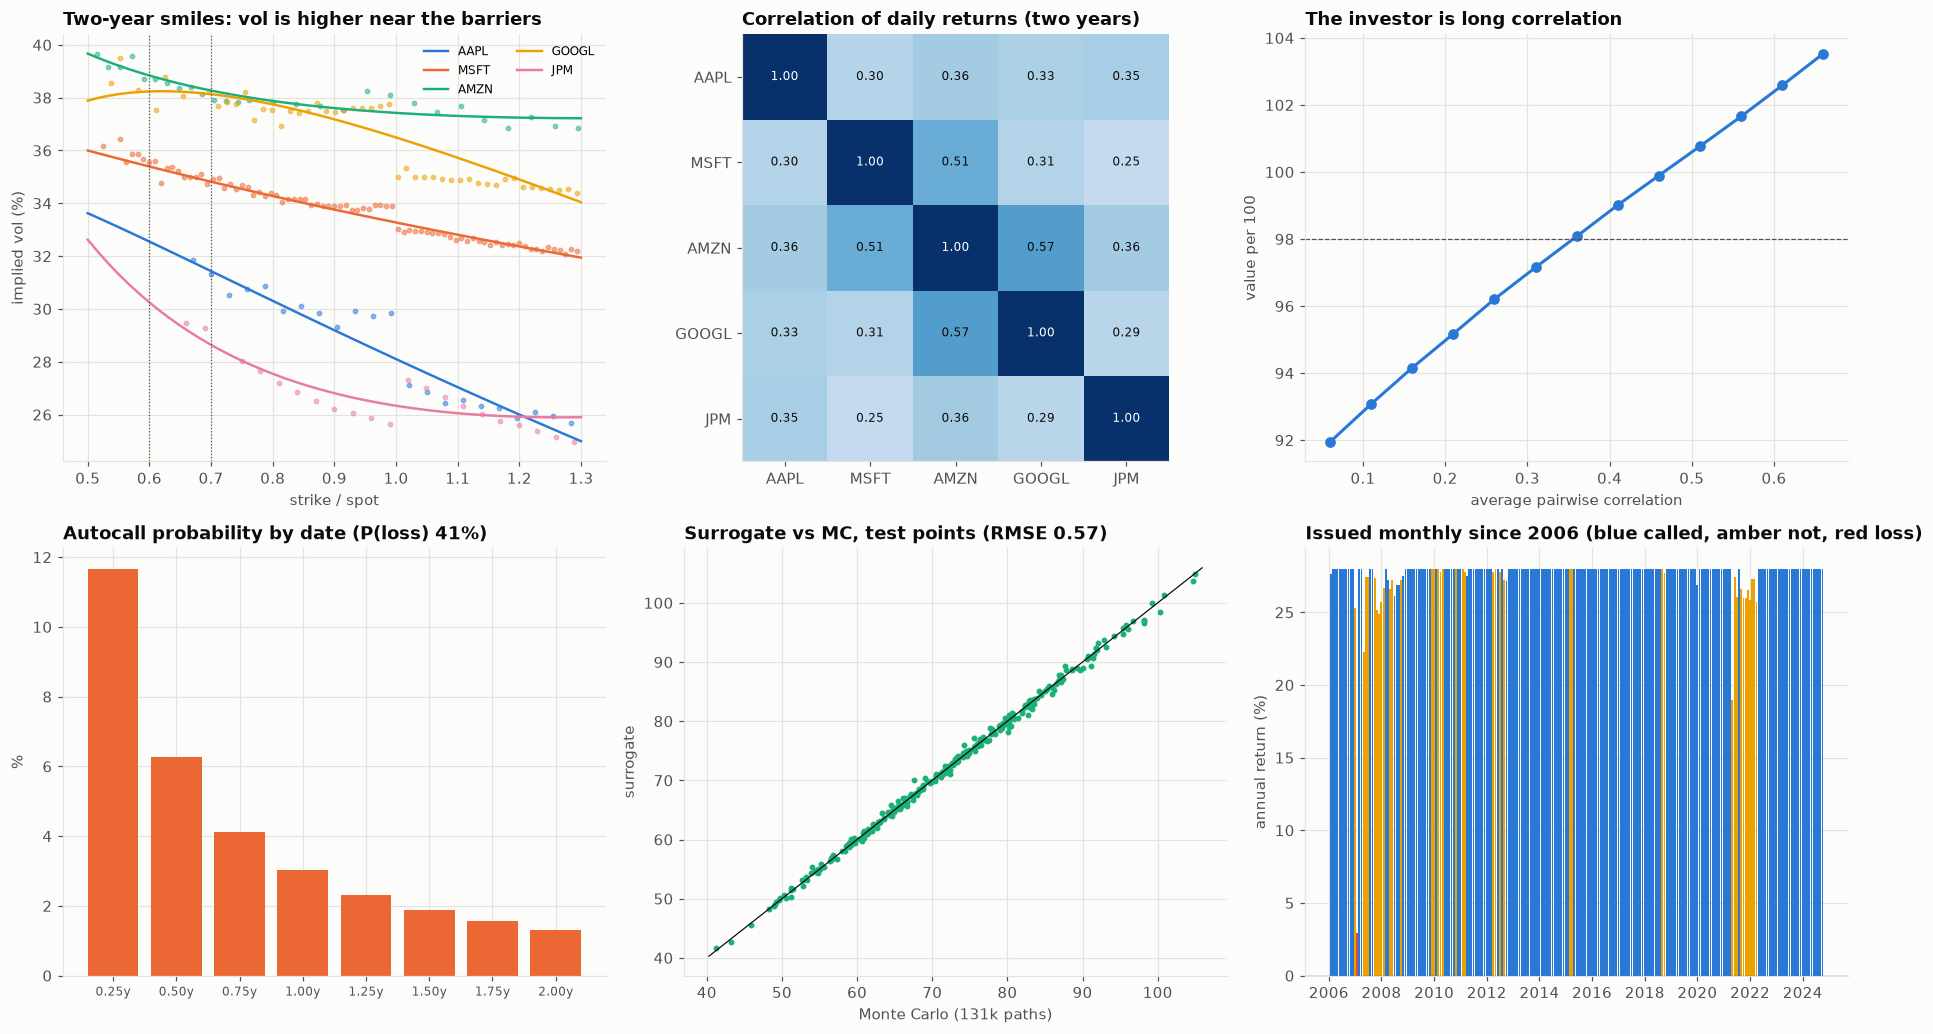

In [13]:
fig, ax = plt.subplots(2, 3, figsize=(17, 9.5))
a = ax[0, 0]
for tk, c in zip(TICKERS, PALETTE):
    g = smile_pts[smile_pts["ticker"] == tk]
    m = np.linspace(0.5, 1.3, 50)
    a.scatter(g["strike"] / SPOT[tk], g["iv"] * 100, s=8, color=c, alpha=0.5)
    a.plot(
        m,
        100
        * np.polyval(
            [VOL.loc[tk, "c2"], VOL.loc[tk, "c1"], VOL.loc[tk, "c0"]],
            np.log(m),
        ),
        color=c,
        label=tk,
        lw=1.6,
    )
for b in (KI_BARRIER, COUPON_BARRIER):
    a.axvline(b, color=INK_2, lw=0.8, ls=":")
a.set_xlabel("strike / spot")
a.set_ylabel("implied vol (%)")
a.legend(fontsize=8, ncol=2)
a.set_title("Two-year smiles: vol is higher near the barriers")
a = ax[0, 1]
im = a.imshow(CORR.to_numpy(), cmap="Blues", vmin=0, vmax=1)
a.set_xticks(range(5), TICKERS)
a.set_yticks(range(5), TICKERS)
for i in range(5):
    for j in range(5):
        a.text(
            j,
            i,
            f"{CORR.iloc[i, j]:.2f}",
            ha="center",
            va="center",
            fontsize=8,
            color="white" if CORR.iloc[i, j] > 0.6 else INK,
        )
a.grid(False)
a.set_title("Correlation of daily returns (two years)")
a = ax[0, 2]
a.plot(sens_corr.index, sens_corr.values, marker="o", color=PALETTE[0])
a.axhline(ISSUE_PRICE, color=INK_2, lw=0.8, ls="--")
a.set_xlabel("average pairwise correlation")
a.set_ylabel("value per 100")
a.set_title("The investor is long correlation")
a = ax[1, 0]
a.bar(call_prob.index, call_prob.values * 100, color=PALETTE[1])
a.set_ylabel("%")
a.tick_params(axis="x", labelsize=8)
a.set_title(
    "Autocall probability by date (P(loss)"
    f" {100 * res['skew-adjusted vols (65% strike)']['P(loss at maturity)']:.0f}%)"
)
a = ax[1, 1]
a.scatter(y_te, pred_te, s=8, color=PALETTE[2])
lim = [y_te.min() - 1, y_te.max() + 1]
a.plot(lim, lim, color=INK, lw=0.8)
a.set_xlabel("Monte Carlo (131k paths)")
a.set_ylabel("surrogate")
a.set_title(
    f"Surrogate vs MC, test points (RMSE {ACC['test RMSE (points)']:.2f})"
)
a = ax[1, 2]
cols = np.where(
    HIST["loss"],
    STATUS["red"],
    np.where(HIST["called"], PALETTE[0], STATUS["amber"]),
)
a.bar(HIST.index, HIST["annual return (%)"], width=25, color=cols)
a.axhline(0, color=INK, lw=0.8)
a.set_ylabel("annual return (%)")
a.set_title("Issued monthly since 2006 (blue called, amber not, red loss)")
fig.tight_layout()
save_fig(fig, "01_worst_of_autocallable")
plt.show()

In [14]:
dash = make_subplots(
    rows=2,
    cols=2,
    subplot_titles=(
        "Value against average correlation (per 100)",
        "Same note issued monthly since 2006: annual return (%)",
        "Surrogate vs Monte Carlo on test points",
        "10-day P&L distribution of a $10mm position (surrogate)",
    ),
)
dash.add_trace(
    go.Scatter(
        x=sens_corr.index,
        y=sens_corr.values,
        mode="lines+markers",
        name="value vs correlation",
        line=dict(color=PALETTE[0]),
    ),
    1,
    1,
)
dash.add_trace(
    go.Bar(
        x=HIST.index,
        y=HIST["annual return (%)"],
        marker_color=list(cols),
        name="realised return",
    ),
    1,
    2,
)
dash.add_trace(
    go.Scatter(
        x=y_te,
        y=pred_te,
        mode="markers",
        marker=dict(size=5, color=PALETTE[2]),
        name="test points",
    ),
    2,
    1,
)
dash.add_trace(
    go.Histogram(
        x=pnl_nn / 1e3,
        nbinsx=60,
        marker_color=PALETTE[3],
        name="10-day P&L ($k)",
    ),
    2,
    2,
)
dash.update_layout(
    height=820,
    width=1400,
    template="simple_white",
    showlegend=False,
    title=(
        f"Worst-of-5 autocallable: coupon {4 * COUPON_Q:.2f}% p.a., 99% 10-day"
        f" VaR ${v99 / 1e3:,.0f}k on $10mm"
    ),
)
save_dashboard(dash, "dashboard")
dash.show()

Dashboard saved: outputs/dashboard.html and .png


## 10. Reading the results and limitations

**What the data say**

**The coupon is high because the risk is high.** With two-year at-the-money volatilities of 26–37% and an average pairwise correlation of 0.36, the note is fair at a coupon of 24.7% a year with at-the-money volatilities and 28.9% with skew-adjusted ones, for a 98% issue price.

It is quoted at 29%. The four-point gap is the price of the **volatility skew**: the put the investor sells sits at the 60–70% strikes, where implied volatilities are 3–4 points higher than at the money.

**Under the pricing measure, a loss is likely.** The risk-neutral probability of ending below the 60% barrier is 41%, with an average loss of 56% of notional when it happens. Only 32% of paths are autocalled, and the expected life is 1.6 years. These are risk-neutral probabilities, which include risk premia, not forecasts, but they show what the coupon is paying for.

**The investor is long correlation and short volatility.** Raising all correlations by 0.10 adds 1.8 points of value; the value runs from 92 at an average correlation of 0.06 to 104 at 0.66. Each stock's vega is about −0.35 points per volatility point (−1.8 in total), and +30% on all volatilities costs 16 points.

Rates barely matter (+0.04 for +25 bp). The deltas (0.13–0.19 per 1% on each stock, 0.77 in total) are largest on Alphabet, Amazon and Microsoft, the names most likely to end as the worst performer. Gamma is negative.

**History looks far better than the model, and that is a trap.** Issued every month since 2006 on these same five stocks, 82% of the 225 notes were autocalled (31% at the first date). Only one, issued in January 2007, lost capital: it repaid 54% plus coupons. The realised loss rate is 0.4%, against 41% under the risk-neutral model. Two effects explain the gap:

- **survivorship:** these are today's five largest US companies, chosen with hindsight after two decades in which they massively outperformed; a basket chosen in 2006 would have included names that later collapsed;
- **equity risk premium:** risk-neutral paths drift at the risk-free rate, real ones drifted far higher.

The annualised returns of about 28% also flatter the note: a call after three months returns the capital early, and it has to be reinvested in a new note at the coupon then available.

**The surrogate is accurate enough for risk and roughly 20,000 times faster.** Trained on 24,000 prices of 4,096 paths each (label noise 0.50 points), the network prices 300 test points with an RMSE of 0.57 points, a mean error of 0.41 and a worst case of 2.4, out of a price range with a standard deviation of 12.4.

One Monte Carlo price with 131,072 paths takes 0.07 seconds; the network takes 3–4 microseconds (the exact speed-up varies from run to run, here between 17,000 and 23,000 times). Its deltas are within 0.01 of the Monte Carlo Greeks for four of the five stocks (0.11 vs 0.13 for JPMorgan), its vegas within 0.02, and its correlation sensitivity is 1.75 against 1.81.

**The 10-day VaR of a $10mm position is $1.9mm (99%), with an ES of $2.2mm.** The worst scenario is the April 2025 tariff shock: the worst stock fell 23% in ten days while volatilities rose by half. On the roughly 160 scenarios checked against full Monte Carlo, the surrogate's P&L has a correlation of 0.9995 and a mean error of $28k.

**Limitations**

- Constant volatility per stock. The skew is used through a single strike, not in the dynamics, so the forward skew and the volatility of volatility that drive autocall pricing are missing. A local-stochastic volatility model is the production standard.
- Correlation is historical (two years of daily returns), not implied. Listed correlation instruments on these names do not exist, so desks mark it with a reserve.
- Dividends are continuous yields, and rates are the flat two-year Treasury yield. Discounting at the issuer's funding rate would add to its margin.
- The surrogate covers one product at issue with a fixed schedule. A book needs time to maturity and the barrier history (coupons already paid) as extra inputs, or one surrogate per product family.
- Two-year implied volatilities move by an assumed 0.4 times the VIX in log terms; the true elasticity varies and is higher in crashes.
- The historical replay uses today's coupon for every issue date; coupons in 2008 or 2020 would have been different.

In [15]:
VOL.drop(columns=["c0", "c1", "c2"]).to_csv(
    OUT_DIR / "implied_vols_and_dividends.csv"
)
CORR.to_csv(OUT_DIR / "correlation_matrix.csv")
FAIR.to_csv(OUT_DIR / "fair_coupon_and_probabilities.csv")
GREEKS.to_csv(OUT_DIR / "greeks.csv")
pd.concat({"correlation": sens_corr, "vol multiplier": sens_vol}).to_csv(
    OUT_DIR / "value_sensitivities.csv", header=["value"]
)
HIST.to_csv(OUT_DIR / "historical_issues_since_2006.csv")
ACC.to_csv(OUT_DIR / "surrogate_accuracy.csv", header=["value"])
SG.to_csv(OUT_DIR / "surrogate_vs_mc_greeks.csv")
RISK.to_csv(OUT_DIR / "var_es_10day.csv", header=["value"])
print("Outputs written:", ", ".join(sorted(p.name for p in OUT_DIR.iterdir())))

Outputs written: 01_worst_of_autocallable.png, correlation_matrix.csv, dashboard.html, dashboard.png, fair_coupon_and_probabilities.csv, greeks.csv, historical_issues_since_2006.csv, implied_vols_and_dividends.csv, surrogate_accuracy.csv, surrogate_vs_mc_greeks.csv, value_sensitivities.csv, var_es_10day.csv


## References

### Finance and regulation

- Bouzoubaa, M., & Osseiran, A. (2010). *Exotic options and hybrids: A guide to structuring, pricing and trading*. Wiley. https://doi.org/10.1002/9781119206965
- Henderson, B. J., & Pearson, N. D. (2011). The dark side of financial innovation: A case study of the pricing of a retail financial product. *Journal of Financial Economics, 100*(2), 227–247. https://doi.org/10.1016/j.jfineco.2010.12.006
- Célérier, C., & Vallée, B. (2017). Catering to investors through security design: Headline rate and complexity. *The Quarterly Journal of Economics, 132*(3), 1469–1508. https://doi.org/10.1093/qje/qjx007
- Glasserman, P. (2004). *Monte Carlo methods in financial engineering*. Springer. https://doi.org/10.1007/978-0-387-21617-1

### Machine learning and deep learning

- Huge, B., & Savine, A. (2020). Differential machine learning. *arXiv*. https://arxiv.org/abs/2005.02347
- Ferguson, R., & Green, A. (2018). Deeply learning derivatives. *arXiv*. https://arxiv.org/abs/1809.02233
- Paszke, A., Gross, S., Massa, F., Lerer, A., Bradbury, J., Chanan, G., … Chintala, S. (2019). PyTorch: An imperative style, high-performance deep learning library. *Advances in Neural Information Processing Systems, 32*. https://arxiv.org/abs/1912.01703